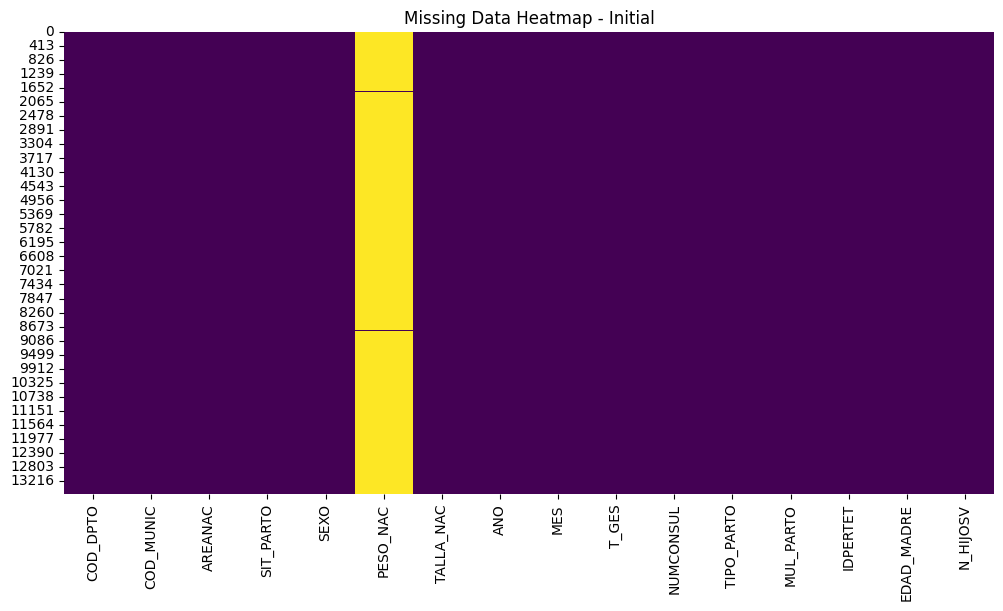

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Generate a heatmap of the null values in the df_births DataFrame
plt.figure(figsize=(12, 6))
sns.heatmap(df_births.isnull(), cbar=False, cmap='viridis')

# Add a title to the heatmap
plt.title('Missing Data Heatmap - Initial')

# Display the plot
plt.show()


In [27]:
print(f"Shape of df_births before dropping all-null columns: {df_births.shape}")
df_births = df_births.dropna(axis=1, how='all')
print(f"Shape of df_births after dropping all-null columns: {df_births.shape}")

Shape of df_births before dropping all-null columns: (13612, 16)
Shape of df_births after dropping all-null columns: (13612, 16)


In [28]:
print(f"Shape of df_births before dropping rows with null values: {df_births.shape}")
df_births = df_births.dropna()
print(f"Shape of df_births after dropping rows with null values: {df_births.shape}")

Shape of df_births before dropping rows with null values: (13612, 16)
Shape of df_births after dropping rows with null values: (48, 16)


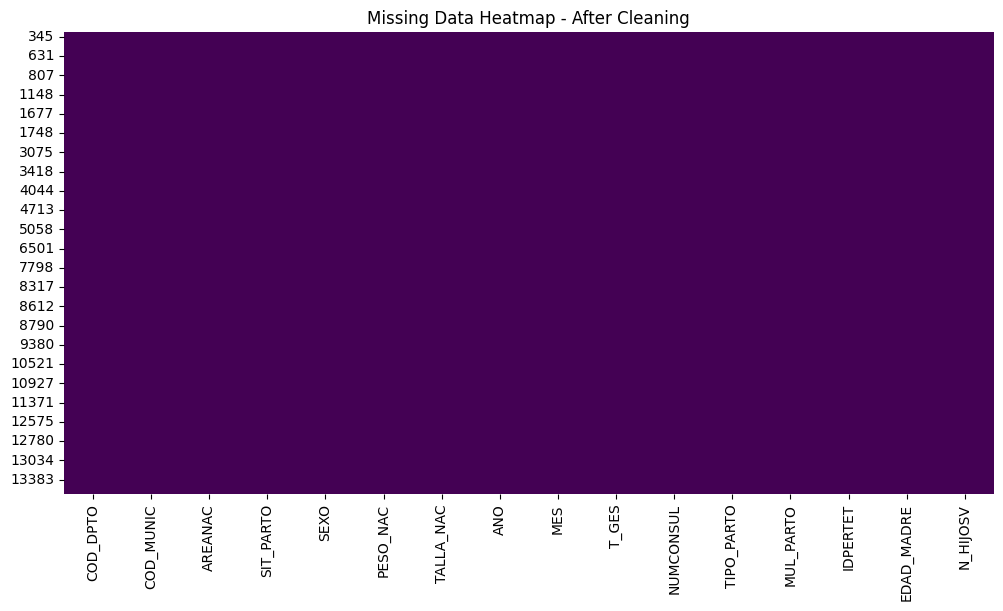

Total null values after cleaning: 0


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate a heatmap of the null values in the cleaned df_births DataFrame
plt.figure(figsize=(12, 6))
sns.heatmap(df_births.isnull(), cbar=False, cmap='viridis')

# Add a title to the heatmap
plt.title('Missing Data Heatmap - After Cleaning')

# Display the plot
plt.show()

# Calculate the total number of null values remaining
total_nulls_after_cleaning = df_births.isnull().sum().sum()
print(f"Total null values after cleaning: {total_nulls_after_cleaning}")

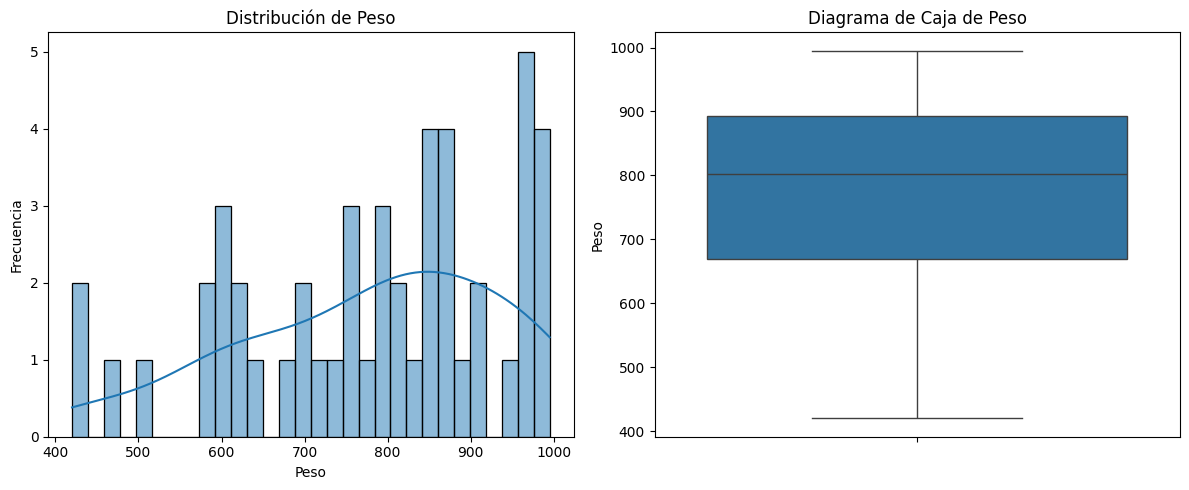

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure and axes for subplots
plt.figure(figsize=(12, 5))

# Histogram for 'PESO_NAC'
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st subplot
sns.histplot(df_births['PESO_NAC'], kde=True, bins=30)
plt.title('Distribución de Peso')
plt.xlabel('Peso')
plt.ylabel('Frecuencia')

# Box plot for 'PESO_NAC'
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd subplot
sns.boxplot(y=df_births['PESO_NAC'])
plt.title('Diagrama de Caja de Peso')
plt.ylabel('Peso')

plt.tight_layout()
plt.show()

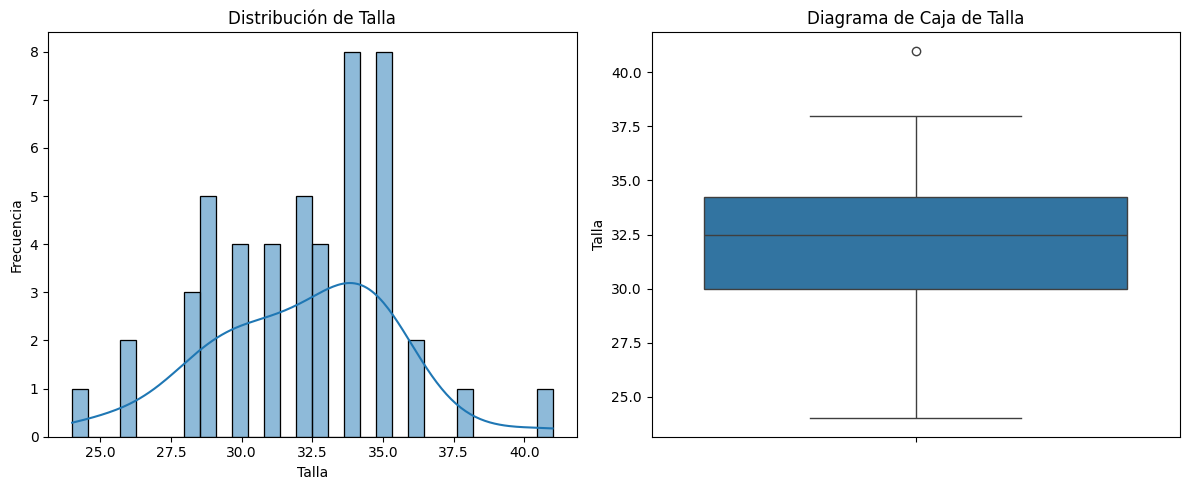

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure and axes for subplots
plt.figure(figsize=(12, 5))

# Histogram for 'TALLA_NAC'
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st subplot
sns.histplot(df_births['TALLA_NAC'], kde=True, bins=30)
plt.title('Distribución de Talla')
plt.xlabel('Talla')
plt.ylabel('Frecuencia')

# Box plot for 'TALLA_NAC'
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd subplot
sns.boxplot(y=df_births['TALLA_NAC'])
plt.title('Diagrama de Caja de Talla')
plt.ylabel('Talla')

plt.tight_layout()
plt.show()

In [32]:
print(f"Shape of df_births before outlier filtering: {df_births.shape}")

# Calculate Q1, Q3, and IQR for 'PESO_NAC'
Q1_peso = df_births['PESO_NAC'].quantile(0.25)
Q3_peso = df_births['PESO_NAC'].quantile(0.75)
IQR_peso = Q3_peso - Q1_peso

# Define bounds for 'PESO_NAC' outliers
lower_bound_peso = Q1_peso - 1.5 * IQR_peso
upper_bound_peso = Q3_peso + 1.5 * IQR_peso

# Calculate Q1, Q3, and IQR for 'TALLA_NAC'
Q1_talla = df_births['TALLA_NAC'].quantile(0.25)
Q3_talla = df_births['TALLA_NAC'].quantile(0.75)
IQR_talla = Q3_talla - Q1_talla

# Define bounds for 'TALLA_NAC' outliers
lower_bound_talla = Q1_talla - 1.5 * IQR_talla
upper_bound_talla = Q3_talla + 1.5 * IQR_talla

# Filter out the outliers
df_births_filtered = df_births[
    (df_births['PESO_NAC'] >= lower_bound_peso) & (df_births['PESO_NAC'] <= upper_bound_peso) &
    (df_births['TALLA_NAC'] >= lower_bound_talla) & (df_births['TALLA_NAC'] <= upper_bound_talla)
]

df_births = df_births_filtered.copy() # Update df_births with the filtered data

print(f"Shape of df_births after outlier filtering: {df_births.shape}")

Shape of df_births before outlier filtering: (48, 16)
Shape of df_births after outlier filtering: (47, 16)


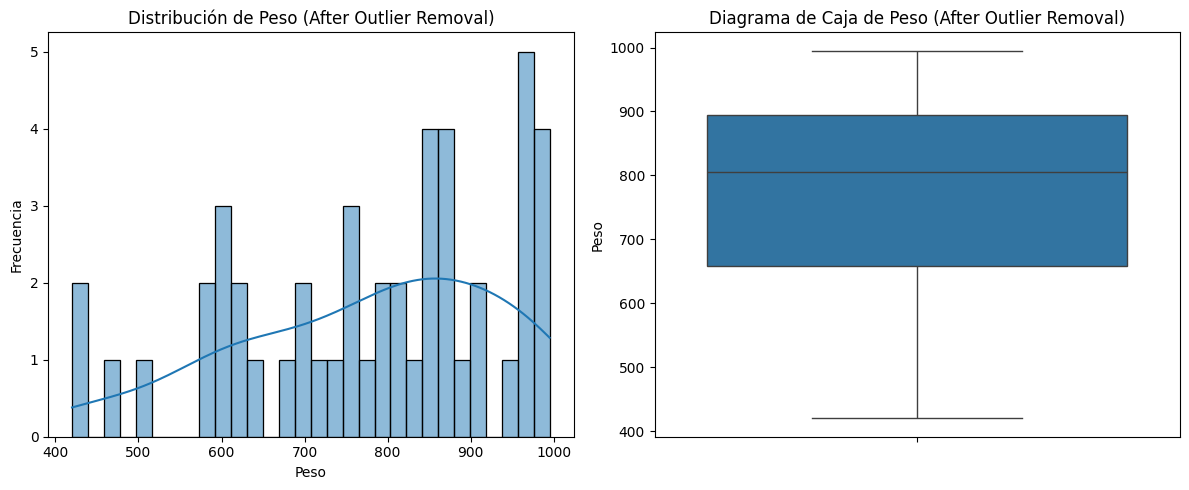

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure and axes for subplots
plt.figure(figsize=(12, 5))

# Histogram for 'PESO_NAC'
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st subplot
sns.histplot(df_births['PESO_NAC'], kde=True, bins=30)
plt.title('Distribución de Peso (After Outlier Removal)')
plt.xlabel('Peso')
plt.ylabel('Frecuencia')

# Box plot for 'PESO_NAC'
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd subplot
sns.boxplot(y=df_births['PESO_NAC'])
plt.title('Diagrama de Caja de Peso (After Outlier Removal)')
plt.ylabel('Peso')

plt.tight_layout()
plt.show()

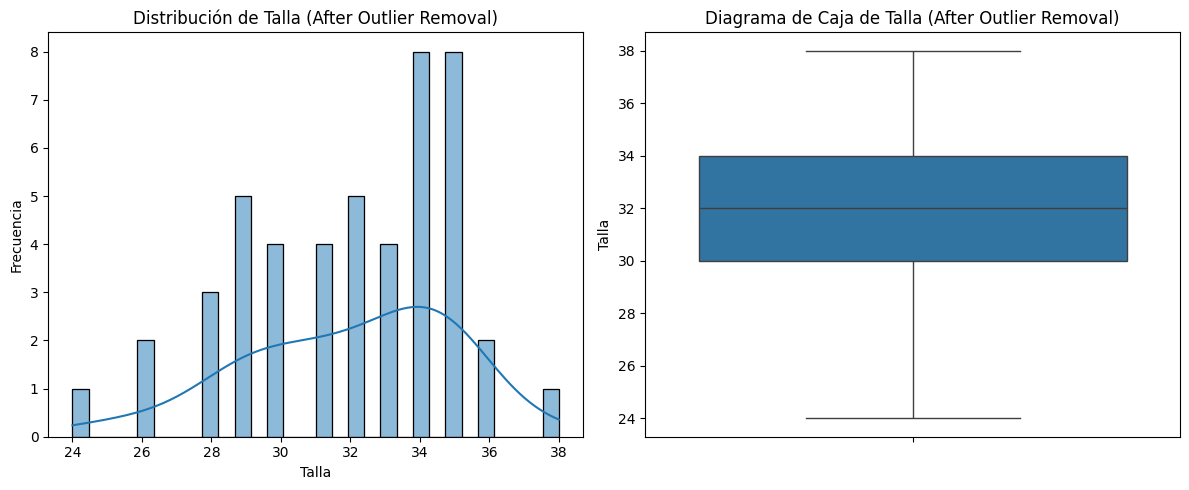

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure and axes for subplots
plt.figure(figsize=(12, 5))

# Histogram for 'TALLA_NAC'
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st subplot
sns.histplot(df_births['TALLA_NAC'], kde=True, bins=30)
plt.title('Distribución de Talla (After Outlier Removal)')
plt.xlabel('Talla')
plt.ylabel('Frecuencia')

# Box plot for 'TALLA_NAC'
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd subplot
sns.boxplot(y=df_births['TALLA_NAC'])
plt.title('Diagrama de Caja de Talla (After Outlier Removal)')
plt.ylabel('Talla')

plt.tight_layout()
plt.show()

Shapiro-Wilk Test: Statistic=0.942, p-value=0.021
  'PESO_NAC' does not look Gaussian (reject H0)


Kolmogorov-Smirnov Test: Statistic=0.110, p-value=0.586
  'PESO_NAC' looks Gaussian (fail to reject H0)


Anderson-Darling Test: Statistic=0.730
  At 15.0% significance level, 'PESO_NAC' does not look Gaussian (critical value 0.536)
  At 10.0% significance level, 'PESO_NAC' does not look Gaussian (critical value 0.611)
  At 5.0% significance level, 'PESO_NAC' looks Gaussian (critical value 0.733)
  At 2.5% significance level, 'PESO_NAC' looks Gaussian (critical value 0.855)
  At 1.0% significance level, 'PESO_NAC' looks Gaussian (critical value 1.017)




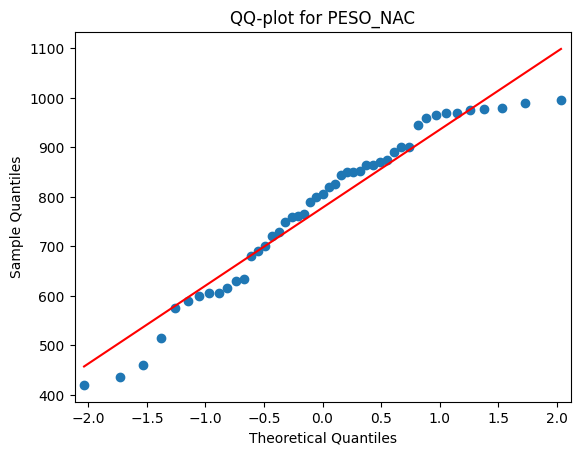

In [35]:
import numpy as np
from scipy.stats import shapiro, kstest, anderson, norm
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 2. Realizar la prueba de Shapiro-Wilk
stat_shapiro, p_shapiro = shapiro(df_births['PESO_NAC'])
print(f"Shapiro-Wilk Test: Statistic={stat_shapiro:.3f}, p-value={p_shapiro:.3f}")
if p_shapiro > 0.05:
    print("  'PESO_NAC' looks Gaussian (fail to reject H0)")
else:
    print("  'PESO_NAC' does not look Gaussian (reject H0)")
print("\n")

# 3. Realizar la prueba de Kolmogorov-Smirnov
mean_peso = df_births['PESO_NAC'].mean()
std_peso = df_births['PESO_NAC'].std()
stat_ks, p_ks = kstest(df_births['PESO_NAC'], 'norm', args=(mean_peso, std_peso))
print(f"Kolmogorov-Smirnov Test: Statistic={stat_ks:.3f}, p-value={p_ks:.3f}")
if p_ks > 0.05:
    print("  'PESO_NAC' looks Gaussian (fail to reject H0)")
else:
    print("  'PESO_NAC' does not look Gaussian (reject H0)")
print("\n")

# 4. Realizar la prueba de Anderson-Darling
result_ad = anderson(df_births['PESO_NAC'], dist='norm')
print(f"Anderson-Darling Test: Statistic={result_ad.statistic:.3f}")
for i in range(len(result_ad.critical_values)):
    sl, cv = result_ad.significance_level[i], result_ad.critical_values[i]
    if result_ad.statistic < cv:
        print(f"  At {sl:.1f}% significance level, 'PESO_NAC' looks Gaussian (critical value {cv:.3f})")
    else:
        print(f"  At {sl:.1f}% significance level, 'PESO_NAC' does not look Gaussian (critical value {cv:.3f})")
print("\n")

# 5. Crear un QQ-plot
sm.qqplot(df_births['PESO_NAC'], line='s')
plt.title('QQ-plot for PESO_NAC')
plt.show()

Shapiro-Wilk Test: Statistic=0.956, p-value=0.076
  'TALLA_NAC' looks Gaussian (fail to reject H0)


Kolmogorov-Smirnov Test: Statistic=0.151, p-value=0.210
  'TALLA_NAC' looks Gaussian (fail to reject H0)


Anderson-Darling Test: Statistic=0.826
  At 15.0% significance level, 'TALLA_NAC' does not look Gaussian (critical value 0.536)
  At 10.0% significance level, 'TALLA_NAC' does not look Gaussian (critical value 0.611)
  At 5.0% significance level, 'TALLA_NAC' does not look Gaussian (critical value 0.733)
  At 2.5% significance level, 'TALLA_NAC' looks Gaussian (critical value 0.855)
  At 1.0% significance level, 'TALLA_NAC' looks Gaussian (critical value 1.017)




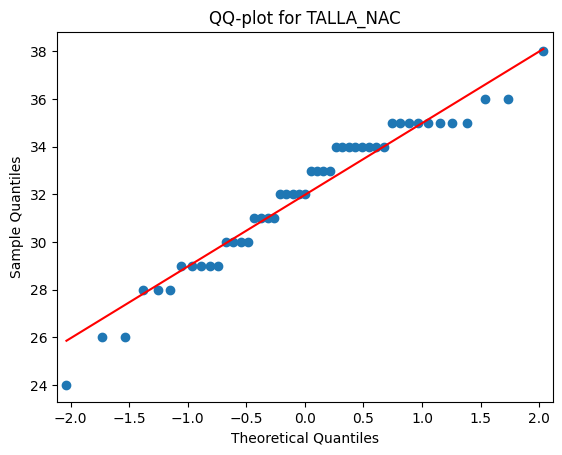

In [36]:
import numpy as np
from scipy.stats import shapiro, kstest, anderson, norm
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Realizar la prueba de Shapiro-Wilk
stat_shapiro, p_shapiro = shapiro(df_births['TALLA_NAC'])
print(f"Shapiro-Wilk Test: Statistic={stat_shapiro:.3f}, p-value={p_shapiro:.3f}")
if p_shapiro > 0.05:
    print("  'TALLA_NAC' looks Gaussian (fail to reject H0)")
else:
    print("  'TALLA_NAC' does not look Gaussian (reject H0)")
print("\n")

# 2. Calcular la media y la desviación estándar de 'TALLA_NAC'
mean_talla = df_births['TALLA_NAC'].mean()
std_talla = df_births['TALLA_NAC'].std()

# 3. Realizar la prueba de Kolmogorov-Smirnov
stat_ks, p_ks = kstest(df_births['TALLA_NAC'], 'norm', args=(mean_talla, std_talla))
print(f"Kolmogorov-Smirnov Test: Statistic={stat_ks:.3f}, p-value={p_ks:.3f}")
if p_ks > 0.05:
    print("  'TALLA_NAC' looks Gaussian (fail to reject H0)")
else:
    print("  'TALLA_NAC' does not look Gaussian (reject H0)")
print("\n")

# 4. Realizar la prueba de Anderson-Darling
result_ad = anderson(df_births['TALLA_NAC'], dist='norm')
print(f"Anderson-Darling Test: Statistic={result_ad.statistic:.3f}")
for i in range(len(result_ad.critical_values)):
    sl, cv = result_ad.significance_level[i], result_ad.critical_values[i]
    if result_ad.statistic < cv:
        print(f"  At {sl:.1f}% significance level, 'TALLA_NAC' looks Gaussian (critical value {cv:.3f})")
    else:
        print(f"  At {sl:.1f}% significance level, 'TALLA_NAC' does not look Gaussian (critical value {cv:.3f})")
print("\n")

# 5. Crear un QQ-plot
sm.qqplot(df_births['TALLA_NAC'], line='s')
plt.title('QQ-plot for TALLA_NAC')
plt.show()